In [51]:
from typing import TypedDict
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from dotenv import load_dotenv
import os
load_dotenv()

True

In [52]:
general_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.environ.get("GROK_API_KEY")
)

gpt_oss = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=os.environ.get("GROK_API_KEY")
)

llama = ChatGroq(
    model="llama-3.1-8b-instant",
    api_key=os.environ.get("GROK_API_KEY")
)

qwen = ChatGroq(
    model="qwen/qwen3.8-27b",
    api_key=os.environ.get("GROK_API_KEY")
)



In [53]:
class Query(TypedDict):
    user_query: str
    query_lvl : str

In [54]:
def classify_query(state : Query):
    response = general_llm.invoke(f"""You are a query complexity classifier. Classify the user's query as exactly one of: simple, medium, or hard.

Use these guidelines:
- simple: A clear, narrow request that can be answered directly with common knowledge and little or no reasoning. Usually requires one step.
- medium: A request requiring several reasoning steps, some explanation, comparison, or applying knowledge to a specific context.
- hard: A request involving substantial multi-step reasoning, multiple constraints or topics, specialized expertise, extensive analysis, or significant ambiguity.

Classify the complexity of answering the query—not its length, wording, or the user's expertise. If the query contains multiple requests, classify based on the most demanding one. Do not answer the query or explain your decision.

Query : {state['user_query']}

Return only one lowercase label: simple, medium, or hard.""")

    return {"query_lvl":response.content}



In [55]:
def llamaLLM(state : Query):
    print("\nSimple Query : Routed to llama-3.1-8b-instant\n")
    response = llama.invoke(state["user_query"])
    print(response.content)

In [56]:
def qwenLLM(state : Query):
    print("\nMedium Query : Routed to qwen/qwen3.8-27b\n")
    response = qwen.invoke(state["user_query"])
    print(response.content)

In [57]:
def gpt_ossLLM(state : Query):
    print("\nHard Query : Routed to openai/gpt-oss-120b\n")
    response = gpt_oss.invoke(state["user_query"])
    print(response.content)

In [66]:
query = {
    "user_query" : "Hi How are you?"
}

In [59]:
classify_query(d)

{'query_lvl': 'medium'}

In [60]:
def route_decision(state:Query):
    reponse = {}
    if state["query_lvl"] == "simple":
        return "llamaLLM"
    if state["query_lvl"] == "medium":
        return "qwenLLM"
    if state["query_lvl"] == "hard":
        return "gpt_ossLLM"

In [61]:
# userQuery -> classify() -> simple,mdeium,hard ->output

In [62]:
route_workflow = StateGraph(Query)

route_workflow.add_node("classify_query",classify_query)
route_workflow.add_node("llamaLLM",llamaLLM)
route_workflow.add_node("qwenLLM",qwenLLM)
route_workflow.add_node("gpt_ossLLM",gpt_ossLLM)



In [63]:
route_workflow.add_edge(START,"classify_query")
route_workflow.add_conditional_edges("classify_query",route_decision,{
    "llamaLLM":"llamaLLM",
    "qwenLLM":"qwenLLM",
    "gpt_ossLLM":"gpt_ossLLM"
})
route_workflow.add_edge("llamaLLM",END)
route_workflow.add_edge("qwenLLM",END)
route_workflow.add_edge("gpt_ossLLM",END)


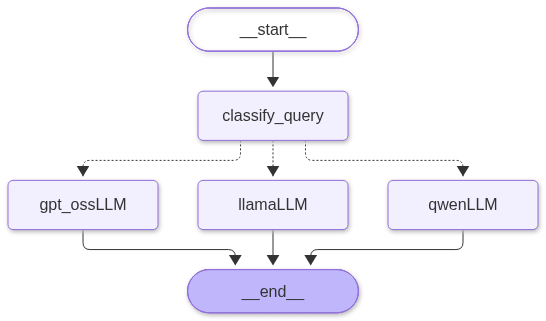

In [67]:
workflow = route_workflow.compile()
workflow

In [68]:
workflow.invoke(query)


Simple Query : Routed to llama-3.1-8b-instant



NotFoundError: Error code: 404 - {'error': {'message': 'The model `llama-3.1-8b-instant` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}

Failed to send compressed multipart ingest: Connection error caused failure to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. Please confirm your internet connection. ConnectionError(MaxRetryError('HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Max retries exceeded with url: /runs/multipart (Caused by ReadTimeoutError("HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Read timed out. (read timeout=3)"))'))
Content-Length: 3345
API Key: lsv2_********************************************25trace=01a19b97-09fd-7973-bebc-6b851c520df6,id=01a19b97-1dfd-7da2-8abf-07979cf66441; trace=01a19b97-09fd-7973-bebc-6b851c520df6,id=01a19b97-1dfc-7063-8107-f64bee6d68f2; trace=01a19b97-09fd-7973-bebc-6b851c520df6,id=01a19b97-09fd-7973-bebc-6b851c520df6
